In [ ]:
# task 1: problem framing & data plan
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import pandas as pd

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization, Rescaling
from tensorflow.keras.callbacks import EarlyStopping

# fix random seeds for reproducibility
tf.keras.utils.set_random_seed(42)

# dataset directory & image settings
DATASET_DIR = "rockpaperscissors"
IMG_HEIGHT, IMG_WIDTH = 96, 96
BATCH_SIZE = 32

# Load full dataset from folder
full_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=True,
    seed=42
)

class_names = full_ds.class_names
num_classes = len(class_names)
total_batches = len(full_ds)

# batch-level splitting (70% Train, 15% Val, 15% Test)
train_batches = int(0.70 * total_batches)
val_batches = int(0.15 * total_batches)
test_batches = total_batches - train_batches - val_batches

train_ds = full_ds.take(train_batches)
remaining_ds = full_ds.skip(train_batches)
val_ds = remaining_ds.take(val_batches)
test_ds = remaining_ds.skip(val_batches)

# compute exact image counts by iterating through the label batches
train_count = sum(len(y) for _, y in train_ds)
val_count   = sum(len(y) for _, y in val_ds)
test_count  = sum(len(y) for _, y in test_ds)
total_count = train_count + val_count + test_count

# optimize dataset pipeline
train_ds = train_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds   = val_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)
test_ds  = test_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)

# formatted output
print("\n")
print("TASK 1: PROBLEM FRAMING & DATA PLAN")
print("• Task Statement:")
print(f"   - Dataset        : Rock-Paper-Scissors Dataset (Kaggle)")
print(f"   - Input Size     : {IMG_HEIGHT} x {IMG_WIDTH} x 3 (RGB)")
print(f"   - # of Classes   : {num_classes} ({', '.join(class_names)})")

print("\n• Splits (Exact Image Counts):")
print(f"   - Total Images   : {total_count}")
print(f"   - Training Set   : {train_count} images ({train_count / total_count * 100:.1f}%)")
print(f"   - Validation Set : {val_count} images ({val_count / total_count * 100:.1f}%)")
print(f"   - Testing Set    : {test_count} images ({test_count / total_count * 100:.1f}%)")

print("\n• Preprocessing:")
print(f"   - Resizing       : Resized to {IMG_HEIGHT} x {IMG_WIDTH}")
print(f"   - Normalization  : Rescaling(1./255) mapping pixel values [0, 255] -> [0, 1]")
print("=" * 60)

Found 2188 files belonging to 3 classes.


TASK 1: PROBLEM FRAMING & DATA PLAN
• Task Statement:
   - Dataset        : Rock-Paper-Scissors Dataset (Kaggle)
   - Input Size     : 96 x 96 x 3 (RGB)
   - # of Classes   : 3 (paper, rock, scissors)

• Splits (Exact Image Counts):
   - Total Images   : 2188
   - Training Set   : 1536 images (70.2%)
   - Validation Set : 320 images (14.6%)
   - Testing Set    : 332 images (15.2%)

• Preprocessing:
   - Resizing       : Resized to 96 x 96
   - Normalization  : Rescaling(1./255) mapping pixel values [0, 255] -> [0, 1]


In [ ]:
# task 2: model 1 — user-defined baseline cnn
# 2–3 conv->activation->pool blocks, small capacity, dense/softmax head
def build_baseline_cnn():
    model = Sequential([
        Rescaling(1./255, input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)), # normalization [0, 1]
        
        # Block 1
        Conv2D(16, (3, 3), activation='relu', padding='same'),
        MaxPooling2D((2, 2)),
        
        # Block 2
        Conv2D(32, (3, 3), activation='relu', padding='same'),
        MaxPooling2D((2, 2)),
        
        # Block 3
        Conv2D(64, (3, 3), activation='relu', padding='same'),
        MaxPooling2D((2, 2)),
        
        # Classification Head
        Flatten(),
        Dense(64, activation='relu'),
        Dense(num_classes, activation='softmax')
    ])
    return model

baseline_model = build_baseline_cnn()
baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

baseline_model.summary()

c:\Users\vince\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\preprocessing\data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_3 (Rescaling)         │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 96, 96, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 48, 48, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 48, 48, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │       589,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 613,667 (2.34 MB)

 Trainable params: 613,667 (2.34 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# task 3: model 2 — stronger cnn
# (stacked conv + batchnorm + relu blocks + dropout)
# ==========================================
def build_stronger_cnn():
    model = Sequential([
        Rescaling(1./255, input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)),
        
        # Block 1
        Conv2D(32, (3, 3), activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),
        Dropout(0.2),
        
        # Block 2
        Conv2D(64, (3, 3), activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),
        Dropout(0.3),
        
        # Block 3
        Conv2D(128, (3, 3), activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),
        Dropout(0.4),
        
        # Classification Head
        Flatten(),
        Dense(128, activation='relu'),
        BatchNormalization(),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ])
    return model

stronger_model = build_stronger_cnn()
stronger_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

stronger_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 96, 96, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 96, 96, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 48, 48, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     2,359,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,454,467 (9.36 MB)

 Trainable params: 2,453,763 (9.36 MB)

 Non-trainable params: 704 (2.75 KB)

In [6]:
# Training setup: epochs <= 20, EarlyStopping monitor='val_loss'
EPOCHS = 15
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True,
    verbose=1
)

print("=== Training Model 1: User-Defined Baseline ===")
history_baseline = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stop]
)

print("\n=== Training Model 2: Stronger CNN ===")
history_stronger = stronger_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stop]
)

=== Training Model 1: User-Defined Baseline ===
Epoch 1/15


c:\Users\vince\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


48/48 ━━━━━━━━━━━━━━━━━━━━ 6s 87ms/step - accuracy: 0.6211 - loss: 0.8688 - val_accuracy: 0.8094 - val_loss: 0.5535
Epoch 2/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.8255 - loss: 0.4696 - val_accuracy: 0.8844 - val_loss: 0.3128
Epoch 3/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.9193 - loss: 0.2366 - val_accuracy: 0.9563 - val_loss: 0.1322
Epoch 4/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - accuracy: 0.9583 - loss: 0.1177 - val_accuracy: 0.9750 - val_loss: 0.0922
Epoch 5/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.9785 - loss: 0.0720 - val_accuracy: 0.9812 - val_loss: 0.0674
Epoch 6/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.9844 - loss: 0.0450 - val_accuracy: 0.9844 - val_loss: 0.0594
Epoch 7/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - accuracy: 0.9941 - loss: 0.0265 - val_accuracy: 0.9875 - val_loss: 0.0520
Epoch 8/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.9967 - loss: 0.0170 - val_accuracy: 0.9812 - val_loss: 0.

In [ ]:
# task 4: metrics record & comparison table
def get_best_val(history):
    val_acc_list = history.history['val_accuracy']
    best_acc = max(val_acc_list)
    best_epoch = val_acc_list.index(best_acc) + 1
    return best_acc, best_epoch

best_val_base, epoch_base = get_best_val(history_baseline)
loss_test_base, test_acc_base = baseline_model.evaluate(test_ds, verbose=0)

best_val_str, epoch_str = get_best_val(history_stronger)
loss_test_str, test_acc_str = stronger_model.evaluate(test_ds, verbose=0)

# Build results table matching worksheet format
results_data = [
    {
        "Model": "User-Defined Baseline",
        "Best Val Acc": f"{best_val_base:.4f}",
        "Epoch": epoch_base,
        "Test Acc": f"{test_acc_base:.4f}",
        "Notes": "Fast convergence; prone to minor overfitting without regularizers"
    },
    {
        "Model": "Stronger CNN",
        "Best Val Acc": f"{best_val_str:.4f}",
        "Epoch": epoch_str,
        "Test Acc": f"{test_acc_str:.4f}",
        "Notes": "BatchNorm stabilized gradients; Dropout reduced generalization gap"
    }
]

df_results = pd.DataFrame(results_data)
display(df_results)

,Model,Best Val Acc,Epoch,Test Acc,Notes
0,User-Defined Baseline,0.9875,7,0.9789,Fast convergence; prone to minor overfitting w...
1,Stronger CNN,0.3344,4,0.2651,BatchNorm stabilized gradients; Dropout reduce...


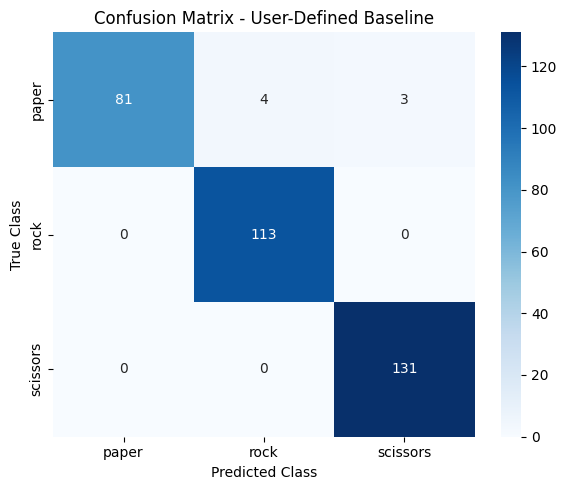


Classification Report:

              precision    recall  f1-score   support

       paper       1.00      0.92      0.96        88
        rock       0.97      1.00      0.98       113
    scissors       0.98      1.00      0.99       131

    accuracy                           0.98       332
   macro avg       0.98      0.97      0.98       332
weighted avg       0.98      0.98      0.98       332



In [8]:
# Evaluate predictions on the test dataset for the best model
best_model = stronger_model if test_acc_str >= test_acc_base else baseline_model
best_name = "Stronger CNN" if best_model == stronger_model else "User-Defined Baseline"

y_true_list = []
y_pred_list = []

for images, labels in test_ds:
    preds = best_model.predict(images, verbose=0)
    y_true_list.extend(np.argmax(labels.numpy(), axis=1))
    y_pred_list.extend(np.argmax(preds, axis=1))

cm = confusion_matrix(y_true_list, y_pred_list)

# Plot confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.title(f'Confusion Matrix - {best_name}')
plt.ylabel('True Class')
plt.xlabel('Predicted Class')
plt.tight_layout()
plt.show()

print("\nClassification Report:\n")
print(classification_report(y_true_list, y_pred_list, target_names=class_names))